# Exploring the SDSS stellar classification dataset

Inspect the survey columns, class labels, and correlations before modeling. The [project README](../README.md) covers the dataset and how to run the four classifiers.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
# The notebook works from the project root, its notebooks folder, or Kaggle.
candidates = [
    Path("data/star_classification.csv"),
    Path("../data/star_classification.csv"),
    Path("/kaggle/input/stellar-classification-dataset-sdss17/star_classification.csv"),
]
dataset = next((path for path in candidates if path.is_file()), None)
if dataset is None:
    raise FileNotFoundError("Download star_classification.csv into the project's data folder.")
stellar = pd.read_csv(dataset)
stellar.head()

In [4]:
# data info + general stats 
stellar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

In [5]:
stellar.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


In [6]:
stellar['obj_ID'].nunique(), stellar['spec_obj_ID'].nunique()

(78053, 100000)

In [7]:
# classification: encoding 
stellar["class"]=[0 if i == "GALAXY" else 1 if i == "STAR" else 2 for i in stellar["class"]]

In [8]:
stellar["class"].unique()

array([0, 2, 1])

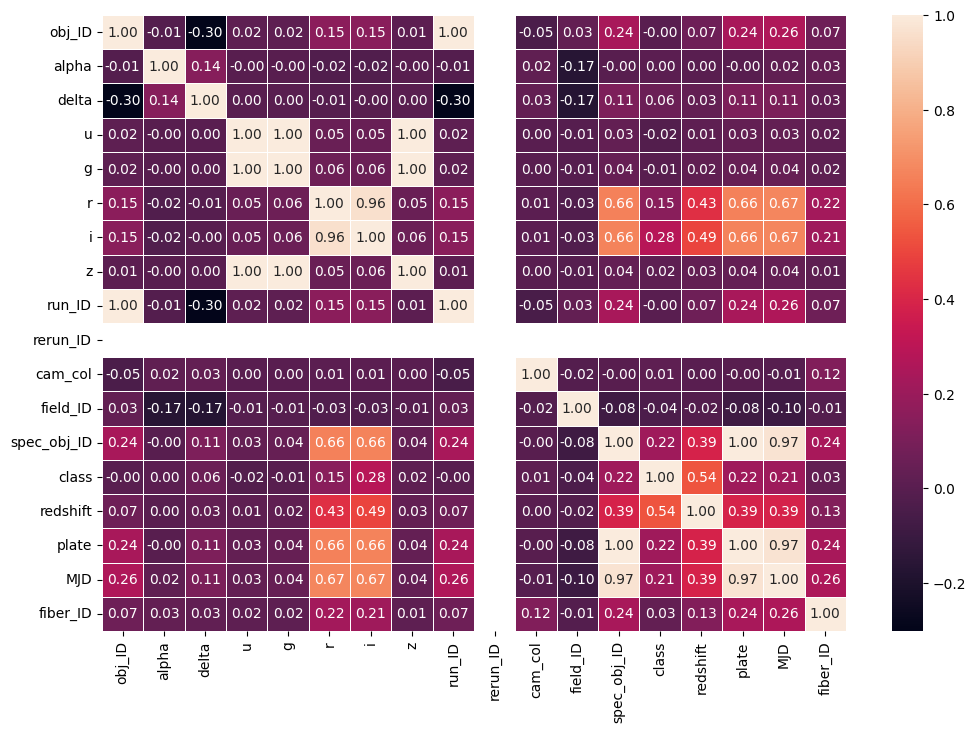

In [12]:
f,ax = plt.subplots(figsize=(12,8))
sns.heatmap(stellar.corr(), annot=True, linewidths=0.5, fmt= '.2f', ax=ax)
plt.show()

In [20]:
pd.DataFrame(stellar.corr()['class']).sort_values(by=['class'], ascending=True)

,class
field_ID,-0.038044
u,-0.017701
g,-0.005915
run_ID,-0.000049
obj_ID,-0.000047
alpha,0.004552
cam_col,0.014476
z,0.017352
fiber_ID,0.032053
delta,0.056643


In [4]:
stellar[stellar['g']<-10]

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
79543,1.237649e+18,224.006526,-0.624304,-9999.0,-9999.0,18.1656,18.01675,-9999.0,752,301,2,537,3.731277e+18,STAR,0.000089,3314,54970,162


In [5]:
stellar[stellar['g']>30]

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
16115,1.237665e+18,145.757641,31.869546,18.85410,31.60224,17.28707,16.93230,16.35421,4518,301,6,125,1.176025e+19,GALAXY,0.767975,10445,58158,807
21245,1.237664e+18,22.566355,0.950467,30.66039,30.60700,29.37411,30.25009,16.82299,4263,301,6,266,8.802546e+18,STAR,-0.000456,7818,56989,947


In [6]:
stellar[stellar['u']>30]

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
21245,1.237664e+18,22.566355,0.950467,30.66039,30.60700,29.37411,30.25009,16.82299,4263,301,6,266,8.802546e+18,STAR,-0.000456,7818,56989,947
56693,1.237661e+18,120.265645,23.563929,32.78139,14.15644,13.36123,26.30939,13.76284,3605,301,4,74,1.423298e+18,QSO,1.658421,1264,52707,584
